# Laplace Transforms with SymPy

Laplace transforms turn linear differential equations into algebraic equations, which is especially handy when the independent variable appears inside complicated functions. This notebook uses **SymPy** to compute transforms and inverse transforms.

$$\mathcal{L}\{f(t)\} = F(s) = \int_0^\infty f(t)\,e^{-st}\,dt$$

This block of code sets up the needed modules and defines the symbols t and s that we use for Laplace Transforms. Run it before anything else.

In [2]:
import sympy as sp
from sympy import exp, cos, sin, laplace_transform, inverse_laplace_transform, Eq, symbols
sp.init_printing()

t = symbols('t', positive=True)
s = symbols('s')

## Examples

These two examples show code for taking Laplace transform and Inverse Laplace Transform

**Transform of** $e^{-2t}$. `noconds=True` returns just the expression, without the convergence conditions.

In [3]:
laplace_transform(exp(-2*t), t, s, noconds=True)

**Inverse transform of** $\dfrac{4}{s^2+4}$ 

In [4]:
inverse_laplace_transform(4/(s**2 + 4), s, t)

---
## Problem 1: Transform of $t\,e^{-2t}\cos(3t)$

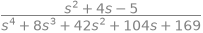

In [5]:
f1 = t*exp(-2*t)*cos(3*t)
F1 = sp.simplify(laplace_transform(f1, t, s, noconds=True))
F1

**Check by hand.** Since $\mathcal{L}\{\cos 3t\} = \dfrac{s}{s^2+9}$, the frequency shift ($s \to s+2$) accounts for $e^{-2t}$, and multiplying by $t$ corresponds to $-\dfrac{d}{ds}$:

Matches SymPy: True


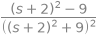

In [6]:
manual = -sp.diff((s + 2)/((s + 2)**2 + 9), s)
print("Matches SymPy:", sp.simplify(manual - F1) == 0)
sp.simplify(manual)

**Answer:**

$$\mathcal{L}\{t e^{-2t}\cos 3t\} = \frac{(s+2)^2-9}{\left((s+2)^2+9\right)^2}$$

---
## Problem 2: Inverse transform of $\dfrac{5-2s}{s^2-s-2}$

In [7]:
F2 = (5 - 2*s)/(s**2 - s - 2)
sp.apart(F2, s)   # partial fractions

In [8]:
f2 = inverse_laplace_transform(F2, s, t)
sp.simplify(f2)

**Check by hand.** $s^2-s-2=(s-2)(s+1)$, so $\dfrac{5-2s}{(s-2)(s+1)}=\dfrac{1/3}{s-2}-\dfrac{7/3}{s+1}$.

**Answer:**

$$f(t)=\frac{1}{3}e^{2t}-\frac{7}{3}e^{-t}$$

---
## Problem 3: Solve with Laplace transforms

$$y''+4y=\sin(2t),\qquad y(0)=10,\quad y'(0)=0$$

**Step 1.** Transform both sides using
$\mathcal{L}\{y''\}=s^2Y-s\,y(0)-y'(0)$ and $\mathcal{L}\{\sin 2t\}=\dfrac{2}{s^2+4}$.

In [9]:
Y = symbols('Y')
y0, yp0 = 10, 0

lhs = (s**2*Y - s*y0 - yp0) + 4*Y
rhs = laplace_transform(sin(2*t), t, s, noconds=True)
eq = Eq(lhs, rhs)
eq

**Step 2.** Solve the algebraic equation for $Y(s)$.

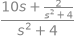

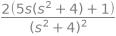

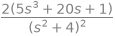

In [21]:
Ys = 1/(s**2+4)*(2/(s**2 + 4) + 10*s) # sp.solve(eq, Y)[0]
display(Ys)
display(sp.simplify(Ys))

Yss = sp.solve(eq, Y)[0]
display(sp.simplify(Yss))

**Step 3.** Invert to get $y(t)$.

In [22]:
yt = sp.simplify(inverse_laplace_transform(Ys, s, t))
display(yt)
display(sp.simplify(inverse_laplace_transform(Yss, s, t)))

**Step 4.** Verify the solution against the ODE and initial conditions.

In [12]:
ode_residual = sp.simplify(sp.diff(yt, t, 2) + 4*yt - sin(2*t))
print("ODE residual:", ode_residual)
print("y(0)  =", sp.simplify(yt.subs(t, 0)))
print("y'(0) =", sp.simplify(sp.diff(yt, t).subs(t, 0)))

ODE residual: sqrt(2)*cos(2*t + pi/4)
y(0)  = 10
y'(0) = 0


**Answer:**

$$y(t)=10\cos 2t+\frac{\sin 2t-2t\cos 2t}{8}$$

The $-\tfrac{t}{4}\cos 2t$ term grows without bound because the forcing frequency equals the natural frequency of the system (**resonance**).

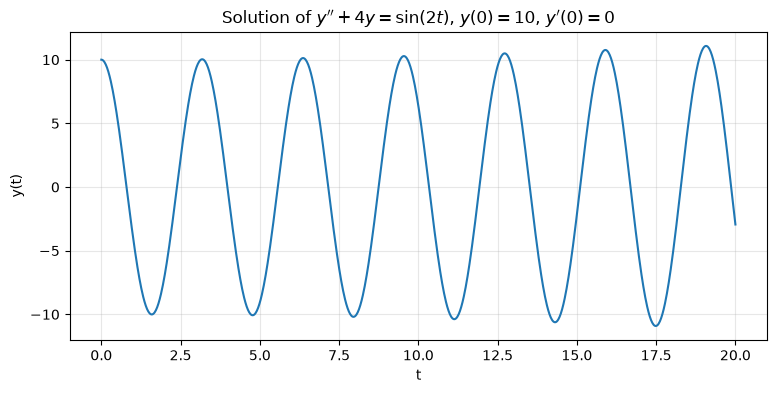

In [13]:
import numpy as np
import matplotlib.pyplot as plt

yf = sp.lambdify(t, yt, 'numpy')
tt = np.linspace(0, 20, 1000)

plt.figure(figsize=(9, 4))
plt.plot(tt, yf(tt))
plt.xlabel('t'); plt.ylabel('y(t)')
plt.title(r"Solution of $y''+4y=\sin(2t)$, $y(0)=10$, $y'(0)=0$")
plt.grid(alpha=0.3)
plt.show()